# Testing on real tower photos

**What this notebook does.** Takes the models trained on single-brick table photos and runs them on real photos of built towers (`real/`). It tries several ways of finding the bricks (whole photo, zoomed tiles, SAM segmentation, a cleaned-up tower crop) and names each find with the classifiers or the gallery lookup. The notebook ends with a written analysis of why it fails.

**Needs:** `real/` (tower photos), `models/`, `runs/`, `data/gallery.npz`, `sam_b.pt`. **Writes:** every figure to `output/`, plus `labeling/brick_sheet.png` and `labeling/thumbs/`.

Imports and the list of real photos. The cell stops with an error if `real/` is empty.

In [1]:
import os
if os.path.basename(os.getcwd()) == 'notebooks': os.chdir('..')   # all paths below are from the repo root
# Run all 3 trained models on real photos in real/ and draw what they find.
# CNN can't find bricks itself -> brick box detector proposes boxes, CNN names each crop.
import csv, glob, cv2, numpy as np, torch, torchvision, matplotlib.pyplot as plt
from ultralytics import YOLO
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
DEV = 'cuda'
CLASSES = sorted({r['element_id'] for r in csv.DictReader(open('data/boxes.csv'))})
em = {r['element_id']: r for r in csv.DictReader(open('data/element_map.csv'))}
name = lambda c: f"{em[c]['part_num']} {em[c]['color']}"
IMGS = sorted(glob.glob('real/*.[jJpP][pPnN]*[gG]'))
assert IMGS, 'put photos (jpg/png) in real/'
CONF = 0.25

Make every `plt.show()` also save the figure to `output/`, so results can be compared later.

In [2]:
import os, time
os.makedirs('output', exist_ok=True)   # from here on, every figure shown by plt.show() is also saved in output/
_show, _n = getattr(plt.show, '_orig', plt.show), [0]   # _orig: re-running this cell must not wrap the wrapper (infinite recursion)
def _save_and_show(*a, **k):
    for n in plt.get_fignums():
        _n[0] += 1; plt.figure(n).savefig(f'output/{time.strftime("%H%M%S")}_{_n[0]:02d}.png', dpi=110, bbox_inches='tight')
    _show(*a, **k)
_save_and_show._orig = _show
plt.show = _save_and_show

**Result:** From here on, every figure is saved automatically.

Load the four trained models. A model trained for an older class count prints a warning instead of crashing.

In [ ]:
def load(f):   # the old models were trained on 41 classes; the data now has 42 (4460b / 2449 split). A stale model becomes None instead of crashing the notebook: retrain in compare.ipynb
    try: return f()
    except Exception as e: print('model not loaded (stale or missing):', str(e).splitlines()[0][:110]); return None

def _cnn():
    m = torchvision.models.resnet18(); m.fc = torch.nn.Linear(512, len(CLASSES))
    m.load_state_dict(torch.load('models/cnn_resnet18.pt')); return m.to(DEV).eval()

def _frcnn():
    m = fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None, min_size=768, max_size=1024)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
    m.load_state_dict(torch.load('models/frcnn_r50.pt')); return m.to(DEV).eval()

box = load(lambda: YOLO('runs/detect/runs/box/weights/best.pt'))   # 1-class brick finder: does not depend on the class count
yolo, cnn, frcnn = load(lambda: YOLO('runs/cmp_yolo/weights/best.pt')), load(_cnn), load(_frcnn)
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1), torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

def run_cnn(img):  # img RGB
    out = []
    for x0, y0, x1, y1 in box.predict(img[..., ::-1], imgsz=1024, conf=CONF, verbose=False)[0].boxes.xyxy.cpu().numpy():
        s = max(x1 - x0, y1 - y0) * 1.15  # same square crop + 15% margin as training
        crop = cv2.resize(cv2.getRectSubPix(img, (int(s), int(s)), ((x0 + x1) / 2, (y0 + y1) / 2)), (224, 224))
        x = ((torch.from_numpy(crop).permute(2, 0, 1).float() / 255 - MEAN) / STD)[None].to(DEV)
        with torch.no_grad(): p = cnn(x).softmax(1)[0]
        out.append(((x0, y0, x1, y1), CLASSES[p.argmax()], p.max().item()))
    return out

def run_yolo(img):
    b = yolo.predict(img[..., ::-1], imgsz=1024, conf=CONF, verbose=False)[0].boxes.cpu()
    return [(tuple(xy), CLASSES[int(c)], float(s)) for xy, c, s in zip(b.xyxy.numpy(), b.cls, b.conf)]

def run_frcnn(img):
    x = torch.from_numpy(img).permute(2, 0, 1).float().div(255).to(DEV)
    with torch.no_grad(): o = frcnn([x])[0]
    return [(tuple(b.cpu().numpy()), CLASSES[int(l) - 1], float(s)) for b, l, s in zip(o['boxes'], o['labels'], o['scores']) if s >= CONF]

**Result:** Any model that prints "not loaded" is stale. Retrain it in compare.ipynb before relying on it.

Run all three models on the whole photo and draw what each one finds.

NameError: name 'run_cnn' is not defined

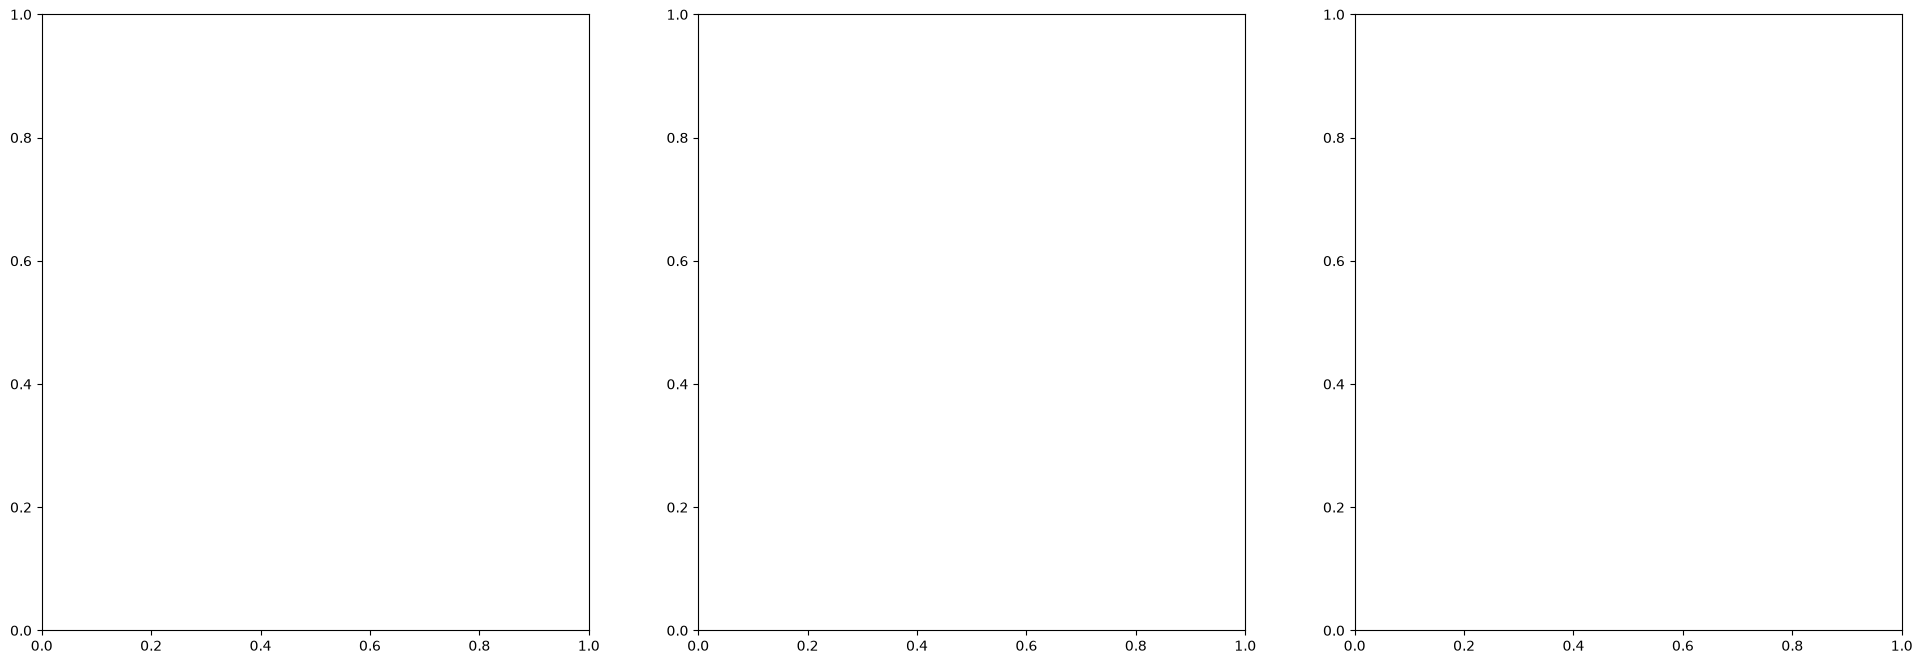

In [4]:
for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 3, figsize=(24, 8))
    for a, (title, fn) in zip(ax, [('box det + CNN', run_cnn), ('YOLO', run_yolo), ('Faster R-CNN', run_frcnn)]):
        dets = fn(img); a.imshow(img); a.set_title(f'{title}: {len(dets)} bricks'); a.axis('off')
        for (x0, y0, x1, y1), c, s in dets:
            a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', lw=2))
            a.text(x0, y0, f'{name(c)} {s:.2f}', color='black', fontsize=7, backgroundcolor='lime')
    fig.suptitle(f); plt.tight_layout(); plt.show()

**Result:** The saved run ended with a `NameError`: one of the stale models was not loaded. Where models did run, whole-photo detection found only a handful of boxes, mostly junk.

Stage 1 "find": cut the photo into overlapping tiles at several zoom levels, so each brick looks as big as in training. Stage 2 "focus": crop each find and name it with the CNN.

In [ ]:
# Stage 1 "find": slide tiles at several zoom levels so each brick looks as big as in training,
# run the detector per tile, map boxes back, merge duplicates.
# Stage 2 "focus": crop each found brick and let the CNN name it (it never sees the neighbours).
from torchvision.ops import nms
FRACS = (1/2, 1/3, 1/4)   # tile size as fraction of the short side; smaller = zoom in more
OVERLAP, EDGE = 0.3, 0.02  # drop boxes touching a tile cut (brick is cut off there, another tile sees it whole)

def tiles(img):
    H, W = img.shape[:2]
    for f in FRACS:
        s = int(min(H, W) * f); st = int(s * (1 - OVERLAP))
        for y in sorted({*range(0, H - s, st), H - s}):
            for x in sorted({*range(0, W - s, st), W - s}):
                yield x, y, s

def find_tiled(img, det=yolo):
    H, W = img.shape[:2]; B, S = [], []
    T = list(tiles(img))
    for i in range(0, len(T), 16):   # chunks keep memory flat
        chunk = T[i:i + 16]
        for (x, y, s), r in zip(chunk, det.predict([np.ascontiguousarray(img[y:y+s, x:x+s, ::-1]) for x, y, s in chunk], imgsz=640, conf=CONF, verbose=False)):
            for (a, b, c, d), sc in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                e = EDGE * s
                if (a < e and x > 0) or (b < e and y > 0) or (c > s - e and x + s < W) or (d > s - e and y + s < H): continue
                B.append([a + x, b + y, c + x, d + y]); S.append(sc)
    if not B: return []
    B, S = torch.tensor(np.array(B)), torch.tensor(np.array(S))
    k = nms(B, S, 0.4)
    return [(tuple(B[i].numpy()), float(S[i])) for i in k]

def name_crops(img, found):
    out = []
    for (x0, y0, x1, y1), s0 in found:
        s = max(x1 - x0, y1 - y0) * 1.15
        crop = cv2.resize(cv2.getRectSubPix(img, (int(s), int(s)), ((x0 + x1) / 2, (y0 + y1) / 2)), (224, 224))
        x = ((torch.from_numpy(crop).permute(2, 0, 1).float() / 255 - MEAN) / STD)[None].to(DEV)
        with torch.no_grad(): p = cnn(x).softmax(1)[0]
        out.append(((x0, y0, x1, y1), CLASSES[p.argmax()], p.max().item()))
    return out

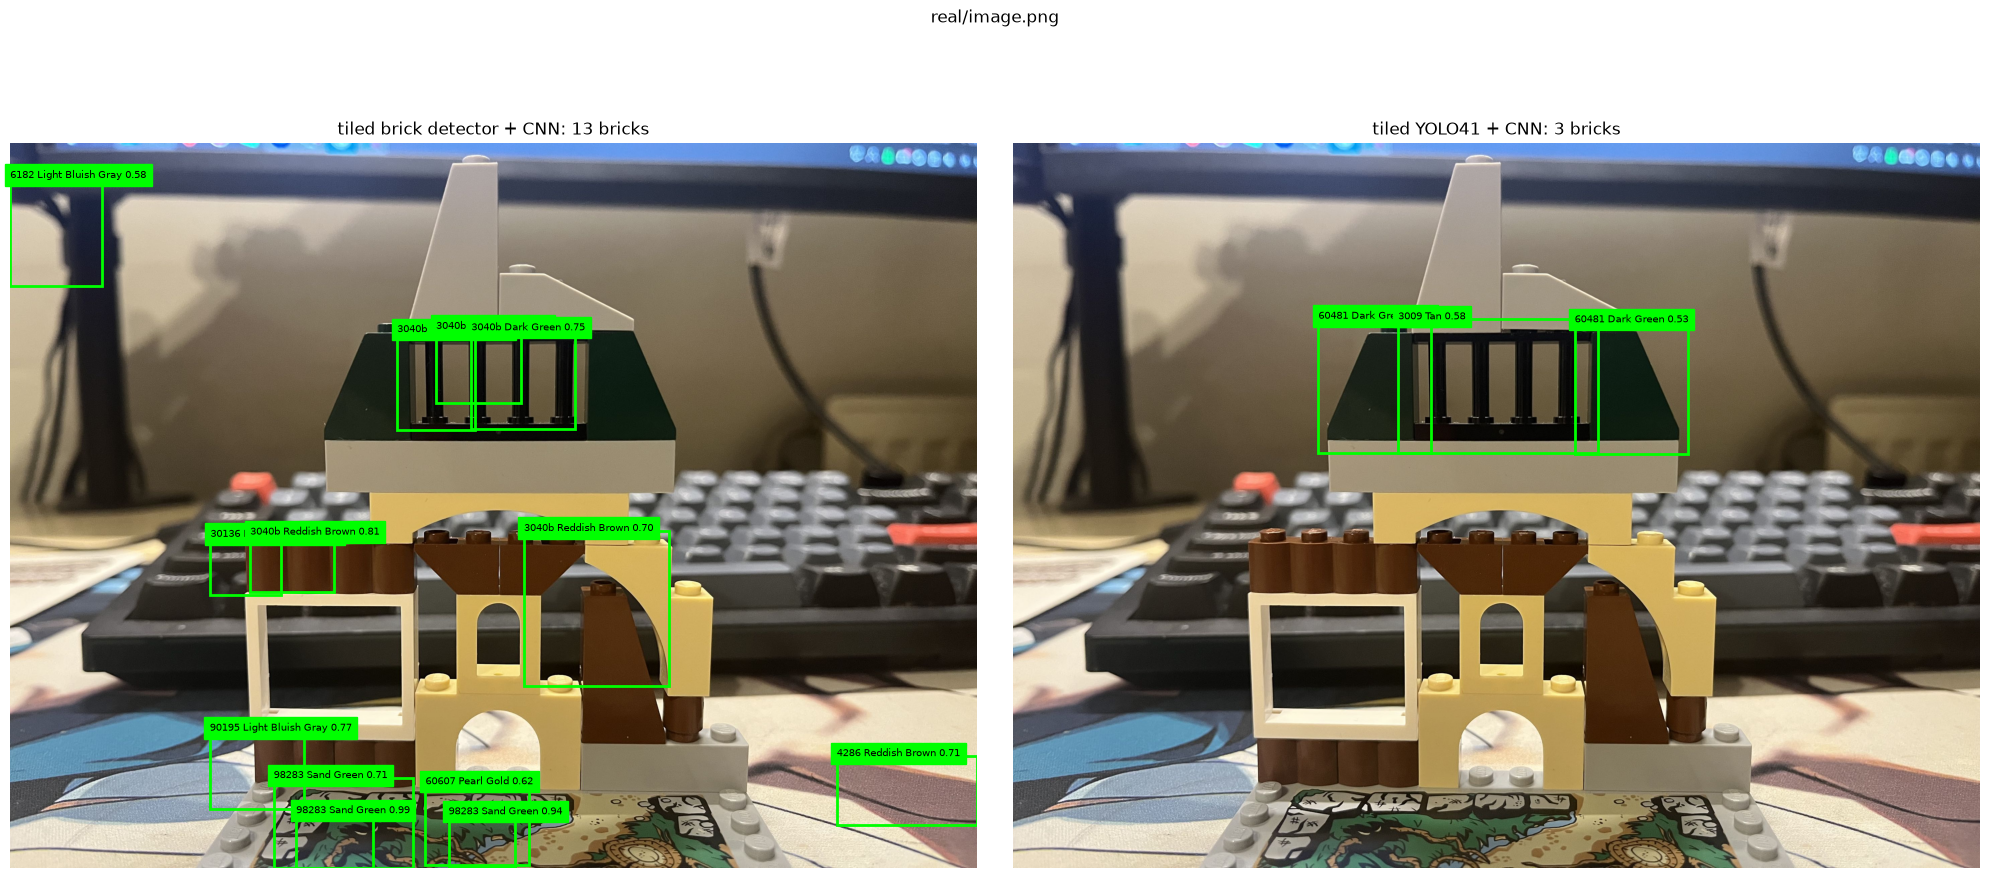

In [ ]:
MIN_NAME = 0.5   # drop boxes the CNN can't name confidently (kills most background junk)
for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB)
    fig, ax = plt.subplots(1, 2, figsize=(20, 10))
    for a, (title, det) in zip(ax, [('tiled brick detector + CNN', box), ('tiled YOLO41 + CNN', yolo)]):
        dets = [d for d in name_crops(img, find_tiled(img, det)) if d[2] >= MIN_NAME]; a.imshow(img); a.set_title(f'{title}: {len(dets)} bricks'); a.axis('off')
        for (x0, y0, x1, y1), c, s in dets:
            a.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color='lime', lw=2))
            a.text(x0, y0, f'{name(c)} {s:.2f}', color='black', fontsize=7, backgroundcolor='lime')
    fig.suptitle(f); plt.tight_layout(); plt.show()

**Result:** Tiling finds many more bricks than the whole photo, but about half of the boxes are background (base-plate studs, desk corners).

The same tiled finder, but naming with the gallery lookup (fingerprint + color) instead of the CNN. Green = named, red = unknown.

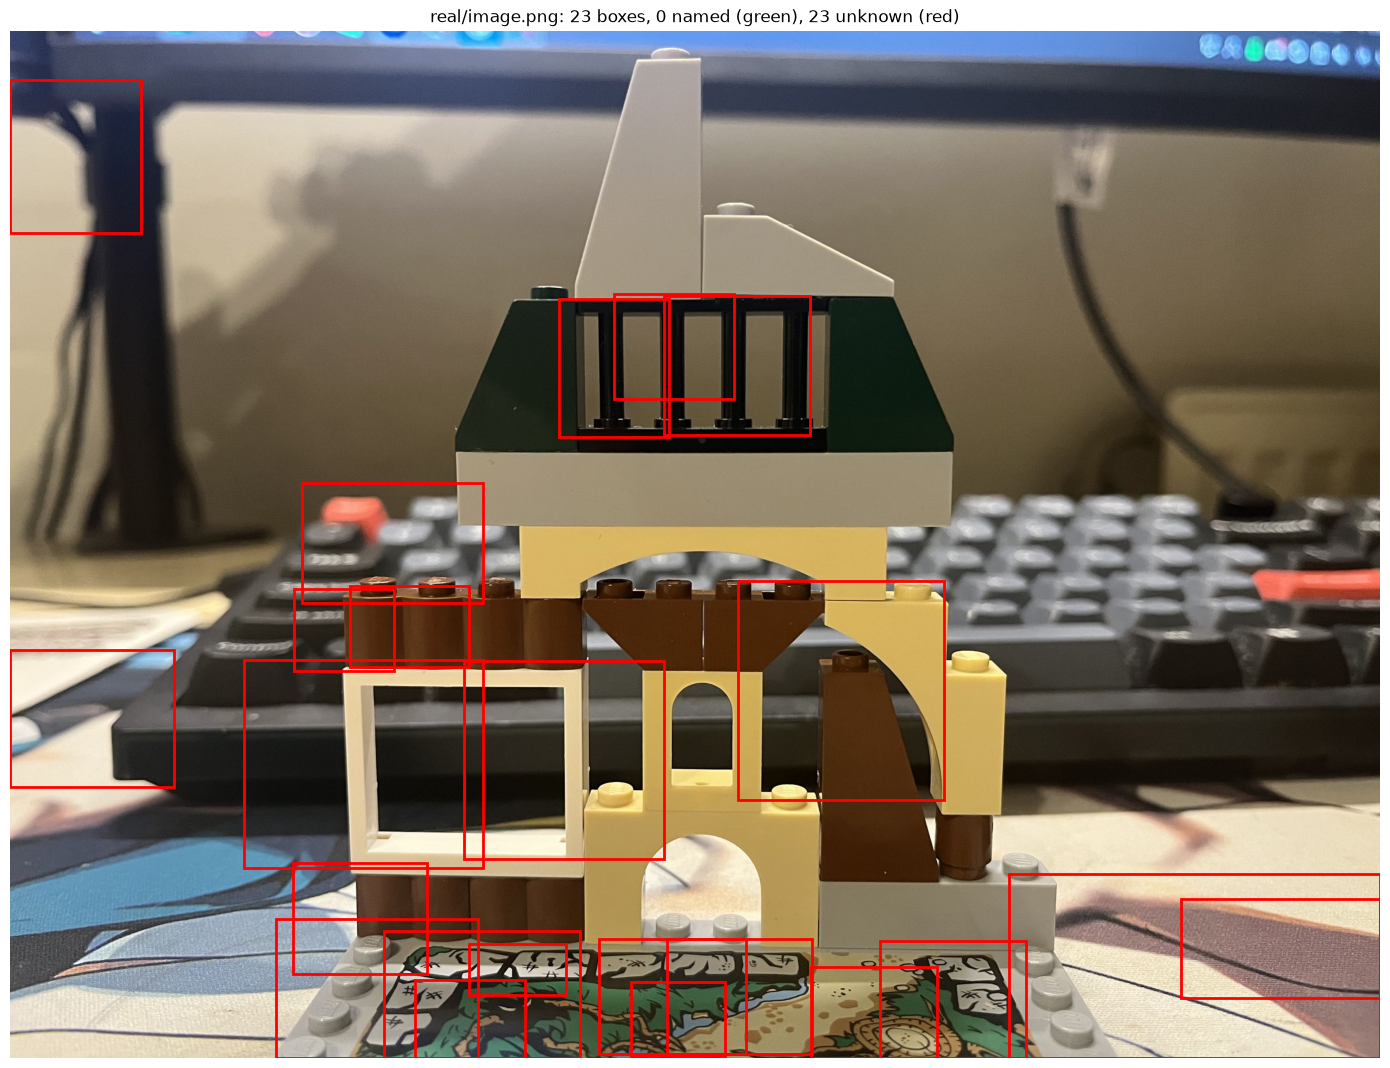

In [ ]:
import sys; sys.path.insert(0, '.'); import lego_lookup as L
emb, gal = L.load_embedder(), L.load_gallery()
cname = {r['lego_id']: r['lego_name'] for r in csv.DictReader(open('data/lego_colors.csv'))}

def run_lookup(img, det=box):   # tiled brick boxes -> fingerprint + color lookup (closed_set: the 41 known pieces)
    found = find_tiled(img, det)
    if not found: return []
    crops = [L.crop_box(img, *b) for b, _ in found]
    res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True)
    return [(b, shape, cname.get(col, col), sim) for (b, _), (shape, sim, col, _) in zip(found, res)]

for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); dets = run_lookup(img)
    known = [d for d in dets if d[1] != 'unknown']
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(img); ax.axis('off')
    ax.set_title(f'{f}: {len(dets)} boxes, {len(known)} named (green), {len(dets) - len(known)} unknown (red)')
    for (x0, y0, x1, y1), shape, col, sim in dets:
        c = 'lime' if shape != 'unknown' else 'red'
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color=c, lw=2))
        if shape != 'unknown': ax.text(x0, y0, f'{shape} {col} {sim:.2f}', color='black', fontsize=7, backgroundcolor='lime')
    plt.tight_layout(); plt.show()

**Result:** Most boxes come out as unknown or uncertain. The lookup's similarity scores on tower crops are far below those on table photos.

Replace the box finder with SAM ("segment everything"). Every mask is cut out onto plain gray, like the table photos, and then looked up.

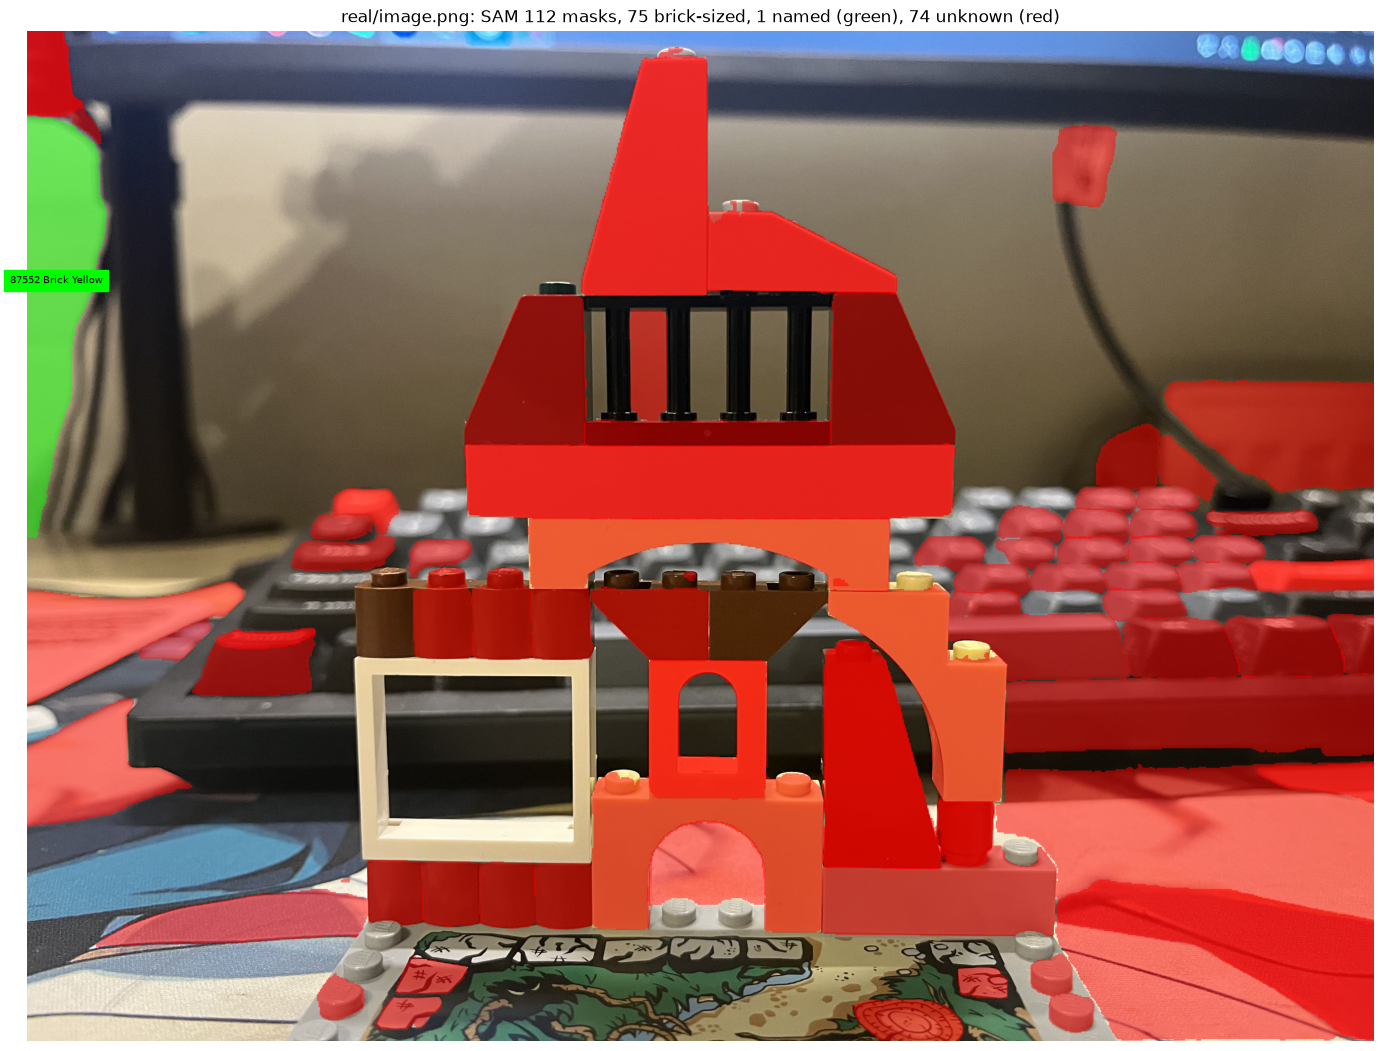

In [ ]:
# SAM as the piece finder: "segment everything" -> one mask per candidate brick -> cut it out on gray -> fingerprint + color lookup.
# Needs only the first (imports) cell above, not the model-loading cell. First run downloads sam_b.pt (~375 MB) into the working dir.
from ultralytics import SAM
import sys; sys.path.insert(0, '.'); import lego_lookup as L
sam = SAM('sam_b.pt')
emb, gal = L.load_embedder(), L.load_gallery()
cname = {r['lego_id']: r['lego_name'] for r in csv.DictReader(open('data/lego_colors.csv'))}
MIN_A, MAX_A = 0.001, 0.15   # mask area as a fraction of the photo: drops specks and the whole tower / background

for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    ms = sam(f, verbose=False)[0].masks.data.cpu().numpy() > 0.5
    keep = []
    for m in ms:
        if m.shape != (H, W): m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
        if MIN_A <= m.mean() <= MAX_A: keep.append(m)
    crops = []
    for m in keep:
        ys, xs = np.where(m); box = (xs.min(), ys.min(), xs.max(), ys.max())
        mm = L.crop_box(m.astype(np.uint8) * 255, *box) > 127
        crops.append(np.where(mm[..., None], L.crop_box(img, *box), 127).astype(np.uint8))   # brick on plain gray, like the table photos
    res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True) if crops else []
    named = sum(r[0] != 'unknown' for r in res)
    over = img.copy()
    for m, (shape, sim, col, _) in zip(keep, res):
        over[m] = (0.5 * over[m] + 0.5 * np.array([0, 255, 0] if shape != 'unknown' else [255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(over); ax.axis('off')
    ax.set_title(f'{f}: SAM {len(ms)} masks, {len(keep)} brick-sized, {named} named (green), {len(keep) - named} unknown (red)')
    for m, (shape, sim, col, _) in zip(keep, res):
        if shape != 'unknown':
            ys, xs = np.where(m); ax.text(xs.mean(), ys.mean(), f'{shape} {cname.get(col, col)}', color='black', fontsize=7, backgroundcolor='lime', ha='center')
    plt.tight_layout(); plt.show()

**Result:** SAM outlines bricks much better than boxes do, but same-colored neighbours often merge into one mask.

Diagnostic: keep only the masks inside the tower and print every best match, colored by similarity.

real/image.png: 38 masks in the tower box | best-match similarity: min 0.82, median 0.87, max 0.91
  >= 0.93: 0 | 0.85-0.93: 30 | < 0.85: 8


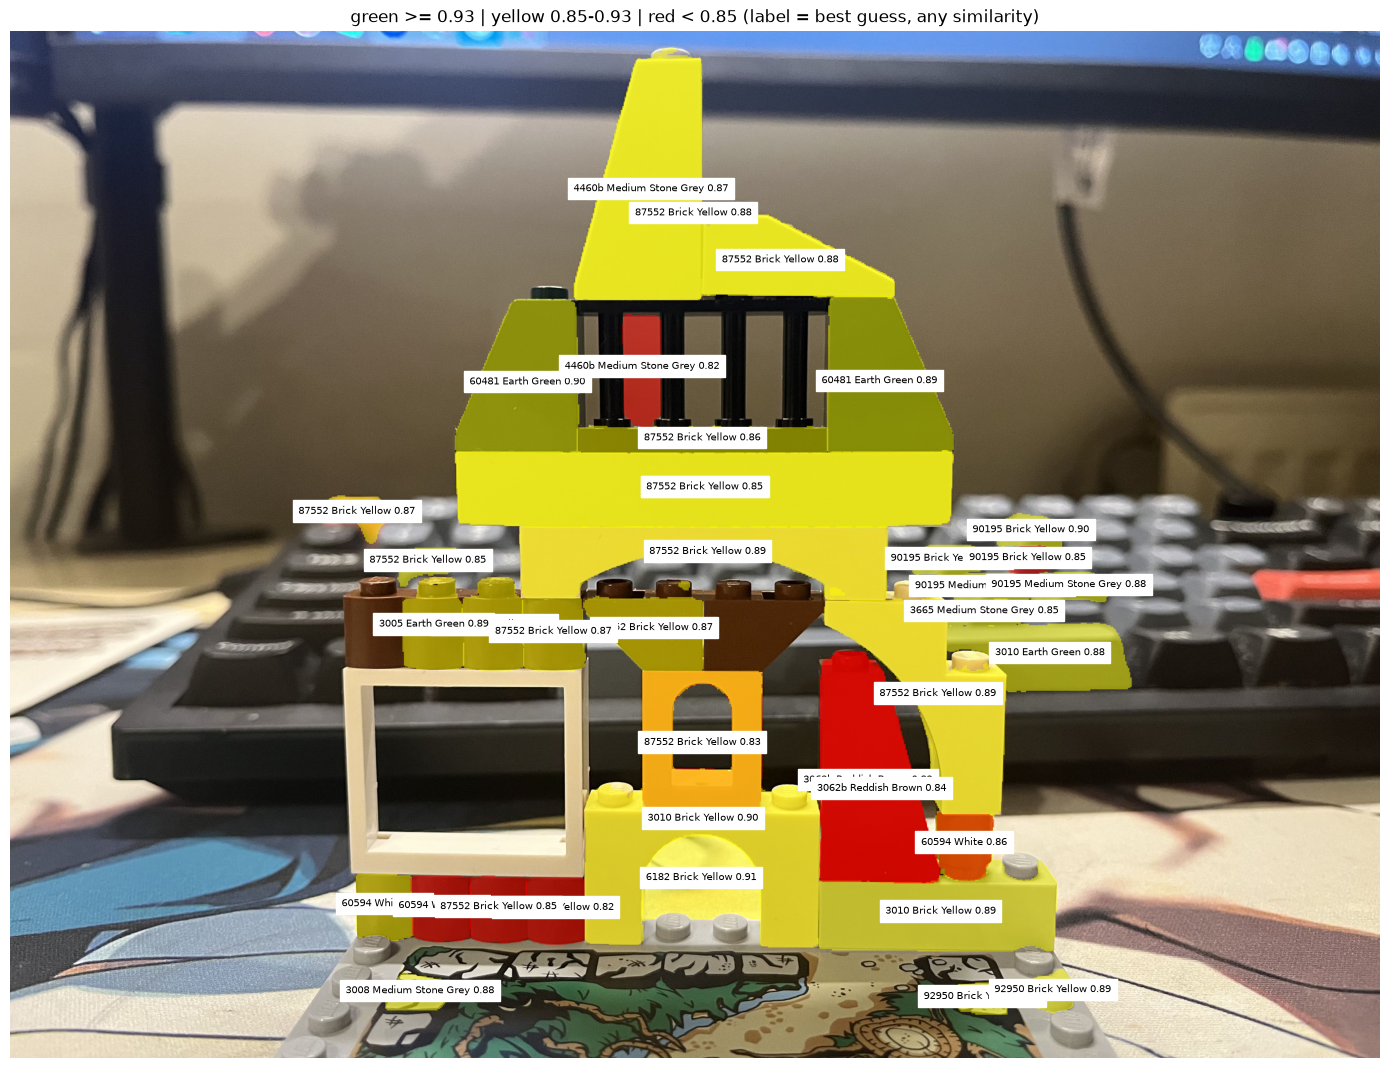

In [ ]:
# Diagnostic: only masks inside the tower, top-1 guess for EVERY mask (no "unknown" cutoff), colored by how close the match is.
# Needs the SAM cell above run first (sam, emb, gal, cname, MIN_A, MAX_A).
TOWER = (0.24, 0.03, 0.78, 0.97)   # tower box as fractions (x0, y0, x1, y1) of the photo. Manual for now: this is the "remove background" step.

for f in IMGS:
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    keep = []
    for m in sam(f, verbose=False)[0].masks.data.cpu().numpy() > 0.5:
        if m.shape != (H, W): m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
        ys, xs = np.where(m)
        if len(xs) and MIN_A <= m.mean() <= MAX_A and TOWER[0] <= xs.mean() / W <= TOWER[2] and TOWER[1] <= ys.mean() / H <= TOWER[3]: keep.append(m)
    crops = []
    for m in keep:
        ys, xs = np.where(m); box = (xs.min(), ys.min(), xs.max(), ys.max())
        mm = L.crop_box(m.astype(np.uint8) * 255, *box) > 127
        crops.append(np.where(mm[..., None], L.crop_box(img, *box), 127).astype(np.uint8))
    res = L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True, shape_min_sim=-1)
    sims = np.array([r[1] for r in res])
    print(f'{f}: {len(keep)} masks in the tower box | best-match similarity: min {sims.min():.2f}, median {np.median(sims):.2f}, max {sims.max():.2f}')
    print(f'  >= 0.93: {(sims >= .93).sum()} | 0.85-0.93: {((sims >= .85) & (sims < .93)).sum()} | < 0.85: {(sims < .85).sum()}')
    over = img.copy()
    for m, r in zip(keep, res):
        over[m] = (0.5 * over[m] + 0.5 * np.array([0, 255, 0] if r[1] >= .93 else [255, 255, 0] if r[1] >= .85 else [255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(over); ax.axis('off')
    ax.set_title('green >= 0.93 | yellow 0.85-0.93 | red < 0.85 (label = best guess, any similarity)')
    for m, (shape, sim, col, _) in zip(keep, res):
        ys, xs = np.where(m); ax.text(xs.mean(), ys.mean(), f'{shape} {cname.get(col, col)} {sim:.2f}', color='black', fontsize=7, backgroundcolor='white', ha='center')
    plt.tight_layout(); plt.show()

**Result:** 38 masks, with best similarities between 0.82 and 0.91 (median 0.87). None reaches the 0.93 a confident match needs.

Clean the photo first: grey out everything outside the tower, crop to it, then run SAM and the lookup again on the bigger bricks.

real/image.png: tower crop 1802x2021, 39 masks | similarity min 0.82, median 0.87, max 0.94 | >= 0.93: 1, 0.85-0.93: 28, < 0.85: 10


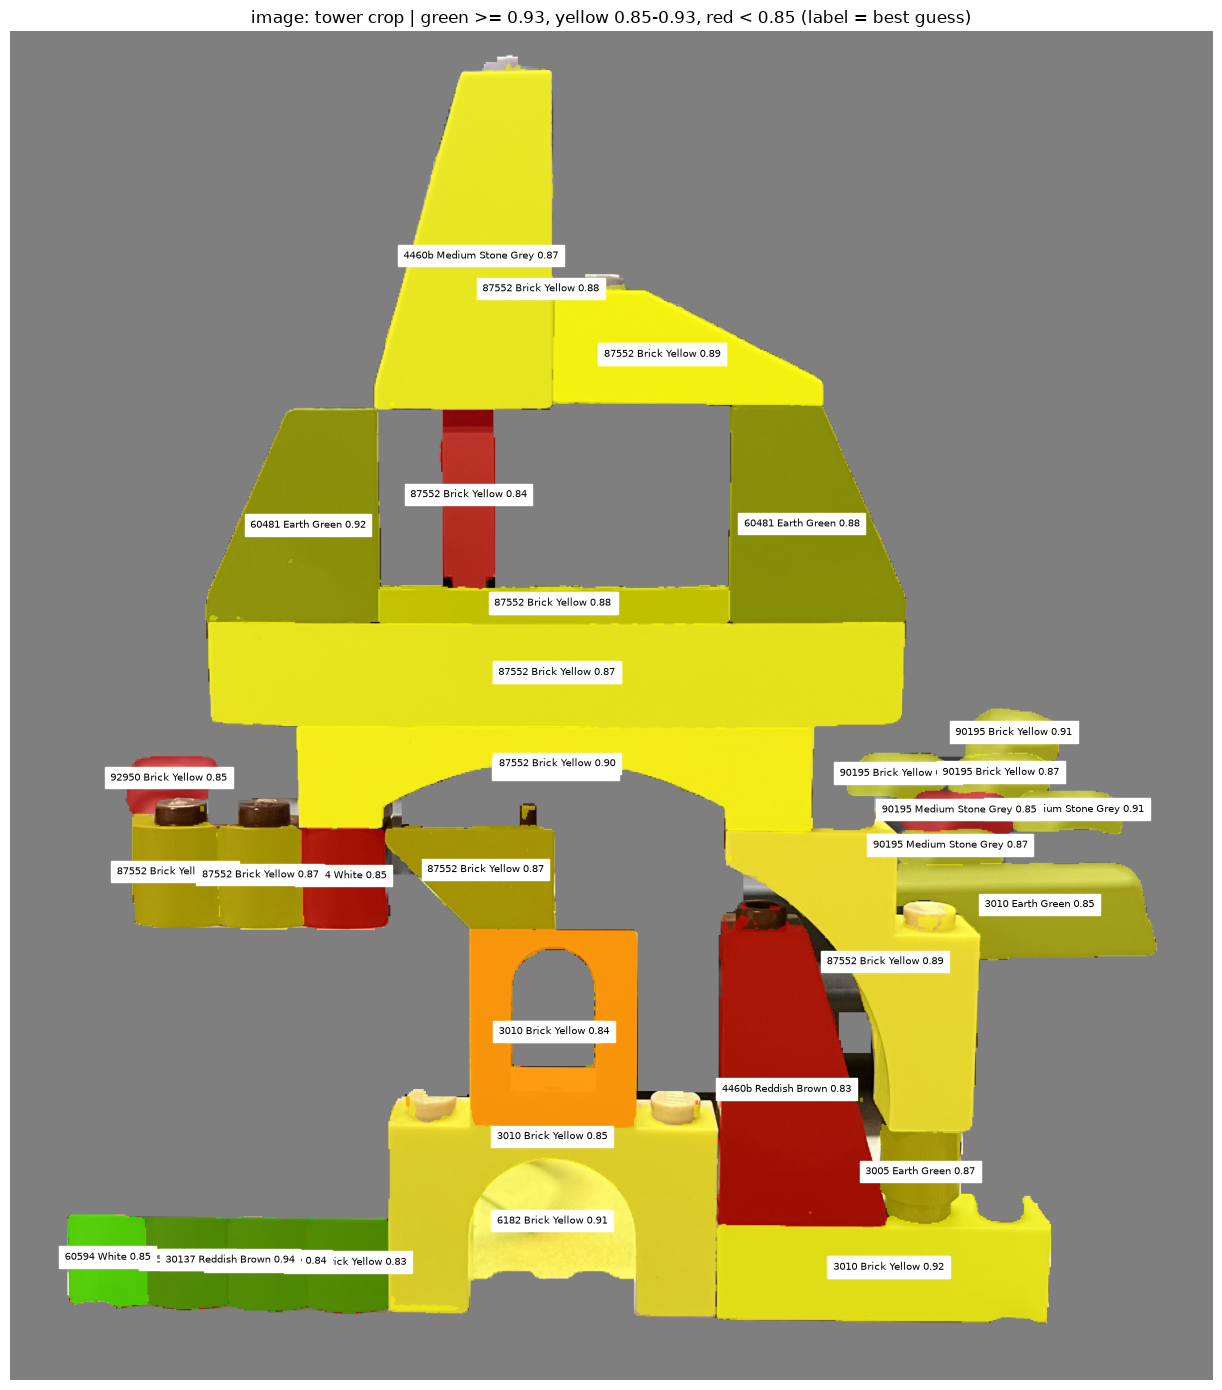

In [ ]:
# Clean the photo first: SAM finds the tower (union of its brick masks inside the TOWER box), everything else goes gray,
# the photo is cropped to the tower, then SAM + lookup run again on that crop (bricks are bigger there, so masks are finer).
# Needs the SAM cell run first (sam, emb, gal, cname, MIN_A, MAX_A) and the diagnostic cell's TOWER box.
def sam_masks(rgb, lo, hi):
    H, W = rgb.shape[:2]; out = []
    for m in sam(np.ascontiguousarray(rgb[..., ::-1]), verbose=False)[0].masks.data.cpu().numpy() > 0.5:
        if m.shape != (H, W): m = cv2.resize(m.astype(np.uint8), (W, H), interpolation=cv2.INTER_NEAREST) > 0
        if lo <= m.mean() <= hi: out.append(m)
    return out

def name_masks(rgb, ms):   # cut each mask out on gray -> fingerprint + color lookup, best guess for every mask
    crops = []
    for m in ms:
        ys, xs = np.where(m); box = (xs.min(), ys.min(), xs.max(), ys.max())
        mm = L.crop_box(m.astype(np.uint8) * 255, *box) > 127
        crops.append(np.where(mm[..., None], L.crop_box(rgb, *box), 127).astype(np.uint8))
    return L.recognize(gal, L.embed(emb, crops), np.array([L.brick_lab(c) for c in crops]), closed_set=True, shape_min_sim=-1) if crops else []

for f in IMGS:
    stem = os.path.splitext(os.path.basename(f))[0]
    img = cv2.cvtColor(cv2.imread(f), cv2.COLOR_BGR2RGB); H, W = img.shape[:2]
    coarse = [m for m in sam_masks(img, MIN_A, MAX_A)
              if TOWER[0] <= np.where(m)[1].mean() / W <= TOWER[2] and TOWER[1] <= np.where(m)[0].mean() / H <= TOWER[3]]
    if not coarse: print(f, ': no masks inside the TOWER box'); continue
    union = cv2.morphologyEx(np.any(coarse, axis=0).astype(np.uint8), cv2.MORPH_CLOSE, np.ones((41, 41), np.uint8))   # fill the thin gaps between bricks
    _, comp, st, _ = cv2.connectedComponentsWithStats(union)
    union = comp == 1 + st[1:, cv2.CC_STAT_AREA].argmax()   # keep only the biggest blob = the tower; drops loose keys and bits
    ys, xs = np.where(union); pad = int(0.03 * max(H, W))
    y0, y1, x0, x1 = max(ys.min() - pad, 0), min(ys.max() + pad, H), max(xs.min() - pad, 0), min(xs.max() + pad, W)
    tower = np.where(union[..., None], img, 127).astype(np.uint8)[y0:y1, x0:x1]
    cv2.imwrite(f'output/{stem}_tower.png', tower[..., ::-1])
    ms = [m for m in sam_masks(tower, 0.002, 0.25) if (tower[m] == 127).all(1).mean() < 0.9]   # drop the gray filler itself
    res = name_masks(tower, ms); sims = np.array([r[1] for r in res])
    print(f'{f}: tower crop {tower.shape[1]}x{tower.shape[0]}, {len(ms)} masks | similarity min {sims.min():.2f}, median {np.median(sims):.2f}, max {sims.max():.2f}'
          f' | >= 0.93: {(sims >= .93).sum()}, 0.85-0.93: {((sims >= .85) & (sims < .93)).sum()}, < 0.85: {(sims < .85).sum()}')
    over = tower.copy()
    for m, r in zip(ms, res):
        over[m] = (0.5 * over[m] + 0.5 * np.array([0, 255, 0] if r[1] >= .93 else [255, 255, 0] if r[1] >= .85 else [255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(over); ax.axis('off')
    ax.set_title(f'{stem}: tower crop | green >= 0.93, yellow 0.85-0.93, red < 0.85 (label = best guess)')
    for m, (shape, sim, col, _) in zip(ms, res):
        ys, xs = np.where(m); ax.text(xs.mean(), ys.mean(), f'{shape} {cname.get(col, col)} {sim:.2f}', color='black', fontsize=7, backgroundcolor='white', ha='center')
    plt.tight_layout(); plt.show()

**Result:** 39 masks, with similarity up to 0.94, but only 1 mask is confident. Cleaning helps the masks more than the naming.

Color first, then shape: read each mask's color from its own pixels, then only compare it with gallery shapes of that color. Top 3 shapes per mask.

image: 39 masks | same shape as before: 17, same color: 18 | similarity median 0.82 | >= 0.93: 1, 0.85-0.93: 10, < 0.85: 28


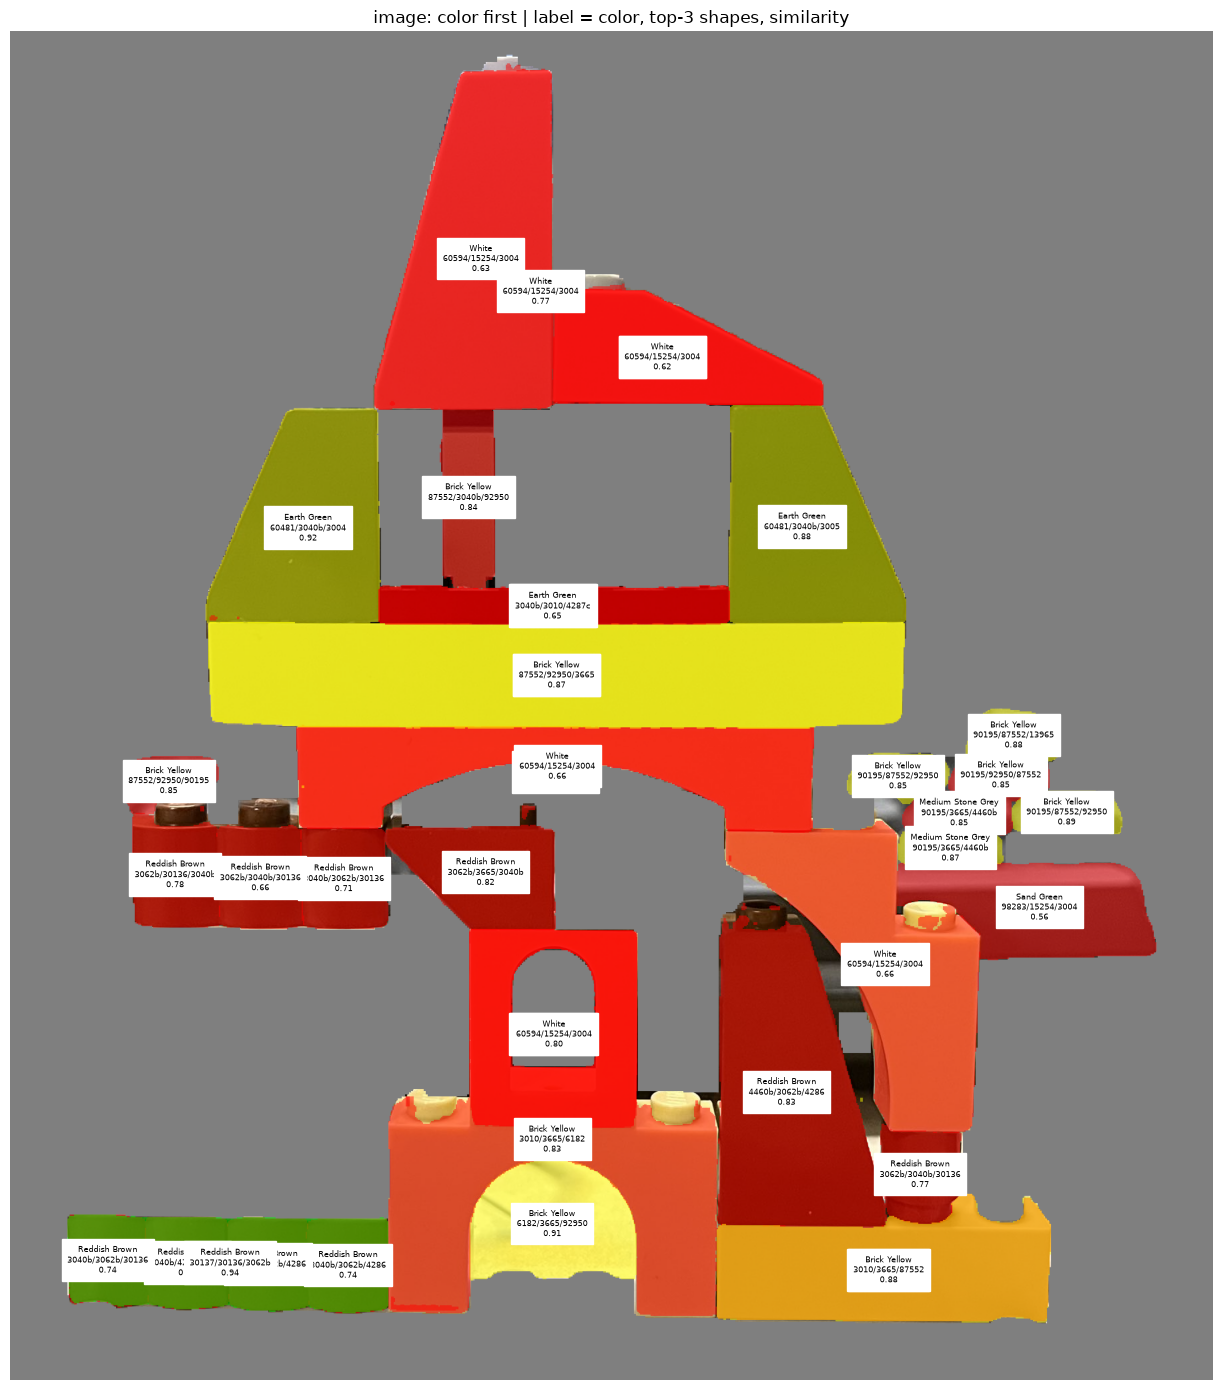

In [ ]:
# Color first, then shape: read the color from the mask's own pixels (no gray cutout, no grabCut), then match the shape
# only against gallery photos of that color (plus color-less renders). Top-3 shapes per mask. No training.
# Needs the cleaned-tower cell run first (output/<stem>_tower.png, sam_masks, name_masks, emb, gal, cname).
def color_first(rgb, ms, k=5):
    lab_img, crops, labs = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB), [], []
    for m in ms:
        ys, xs = np.where(m); box = (xs.min(), ys.min(), xs.max(), ys.max())
        mm = L.crop_box(m.astype(np.uint8) * 255, *box) > 127
        crops.append(np.where(mm[..., None], L.crop_box(rgb, *box), 127).astype(np.uint8))
        e = cv2.erode(m.astype(np.uint8), np.ones((7, 7), np.uint8)) > 0   # skip the mask edge (blur, neighbours)
        labs.append(np.median(lab_img[e if e.sum() > 50 else m], 0))
    out = []
    for v, lab in zip(L.embed(emb, crops), labs):
        d = np.where(gal['color'] != '', np.linalg.norm(gal['lab'] - lab, axis=1), np.inf)
        nc = np.argsort(d)[:k]; col = max(set(gal['color'][nc]), key=list(gal['color'][nc]).count)
        s = np.where((gal['shape'] != '') & np.isin(gal['color'], [col, '']), gal['vec'] @ v, -np.inf)
        top = []
        for i in np.argsort(-s):
            if gal['shape'][i] not in top: top.append(gal['shape'][i])
            if len(top) == 3: break
        out.append((top, col, float(s.max())))
    return out

for f in IMGS:
    stem = os.path.splitext(os.path.basename(f))[0]
    tower = cv2.cvtColor(cv2.imread(f'output/{stem}_tower.png'), cv2.COLOR_BGR2RGB)
    ms = [m for m in sam_masks(tower, 0.002, 0.25) if (tower[m] == 127).all(1).mean() < 0.9]
    base, new = name_masks(tower, ms), color_first(tower, ms); sims = np.array([n[2] for n in new])
    print(f'{stem}: {len(ms)} masks | same shape as before: {sum(b[0] == n[0][0] for b, n in zip(base, new))}, same color: {sum(b[2] == n[1] for b, n in zip(base, new))}'
          f' | similarity median {np.median(sims):.2f} | >= 0.93: {(sims >= .93).sum()}, 0.85-0.93: {((sims >= .85) & (sims < .93)).sum()}, < 0.85: {(sims < .85).sum()}')
    over = tower.copy()
    for m, n in zip(ms, new):
        over[m] = (0.5 * over[m] + 0.5 * np.array([0, 255, 0] if n[2] >= .93 else [255, 255, 0] if n[2] >= .85 else [255, 0, 0])).astype(np.uint8)
    fig, ax = plt.subplots(figsize=(14, 14)); ax.imshow(over); ax.axis('off')
    ax.set_title(f'{stem}: color first | label = color, top-3 shapes, similarity')
    for m, (top, col, sim) in zip(ms, new):
        ys, xs = np.where(m); ax.text(xs.mean(), ys.mean(), f'{cname.get(col, col)}\n{"/".join(top)}\n{sim:.2f}', color='black', fontsize=6, backgroundcolor='white', ha='center', va='center')
    plt.tight_layout(); plt.show()

**Result:** 17 of 39 masks keep the same shape as before, but the median similarity drops to 0.82. Restricting by color does not rescue the shape match.

Build the labelling cheat sheet: one picture per class number, using a real crop or an LDraw render if the piece has no photos.

In [ ]:
# Labeling cheat sheet: number = class in labeling/tower_classes.txt (same order as data/element_map.csv), picture = one real crop of that element.
# Elements with no photo in data/labels.csv are drawn from the LDraw library instead (title says "render"), or left blank if LDraw has no such part.
# Needs only the first (imports) cell. Saves labeling/brick_sheet.png and one labeling/thumbs/NN.png per piece (the labeler tool shows these).
import sys; sys.path.insert(0, '.'); import ldraw_render as R
os.makedirs('labeling/thumbs', exist_ok=True)
ld = {r['bricklink_name']: int(r['ldraw_code']) for r in csv.DictReader(open('data/lego_colors.csv'))}   # element_map.csv uses the BrickLink color names
labs = open('labeling/tower_classes.txt').read().split()
rows = list(csv.DictReader(open('data/element_map.csv'))); assert len(labs) == len(rows) == 45
pick = {}
for r in csv.DictReader(open('data/labels.csv')): pick.setdefault(r['element_id'], []).append(r['path'])
fig, ax = plt.subplots(5, 9, figsize=(27, 16))
for a in ax.flat: a.axis('off')
for a, lab, r in zip(ax.flat, labs, rows):
    num, rest = lab.split('_', 1); note = ''; pic = None
    if r['element_id'] in pick:
        ps = pick[r['element_id']]; pic = cv2.cvtColor(cv2.imread('crops224/' + ps[len(ps) // 2]), cv2.COLOR_BGR2RGB)
    else:
        note = ' (no photo)'
        try:
            im = R.render(r['part_num'], ld[r['color']], rng=np.random.default_rng(0)).astype(float); al = im[..., 3:] / 255
            pic = (im[..., :3] * al + 127 * (1 - al)).astype(np.uint8); note = ' (render)'
        except Exception as e: print(num, r['part_num'], r['color'], 'no picture:', e)
    if pic is not None: a.imshow(pic); cv2.imwrite(f'labeling/thumbs/{num}.png', pic[..., ::-1])
    a.set_title(f"{num}: {rest.replace('_', ' ')}{note}", fontsize=15)
plt.tight_layout(); fig.savefig('labeling/brick_sheet.png', dpi=80, bbox_inches='tight'); plt.show()

**Result:** `labeling/brick_sheet.png` and `labeling/thumbs/` are written for the tower labelling tool.

## Why the models fail on real towers

Measured on one real tower photo (`real/image.png`). Whole-photo detection gave about 5 junk boxes. Tiling plus the CNN confidence filter gave about 13 boxes, roughly half of them real bricks.

**1. Wrong scale.** In every training photo, one brick fills about a third of the frame. In a tower photo each brick is only a few percent of the frame. The detectors never saw small bricks. Tiling helps because it zooms in, but tiles also cut bricks in half.

**2. One brick per photo.** All 6491 training photos hold exactly one brick on a plain table. The models learned "find the single object". They never learned to separate bricks that touch, stack or hide each other. Even the separate 4541873 window parts were labeled as one box.

**3. Different background.** Training backgrounds were a plain table. Real photos have a monitor, a keyboard, a desk and a busy printed base plate. With no negative examples, studs on the base plate and desk corners look like bricks, and the CNN names them with high confidence (e.g. "98283 Sand Green 0.99").

**4. Hidden parts.** In a tower only the front of each brick is visible, and the top, sides and studs are covered. Training photos show whole bricks from above and from the side.

**5. Neighbours in the crop.** In a tower, the square crop the CNN gets includes the neighbouring bricks. Same-colour neighbours (tan on tan, brown on brown) blur where one brick ends and the next begins.

**6. No real test set.** Nothing scores the tower results, since there are no boxed tower photos. Every judgement above is by eye on a single image.

**What would fix it:** training data that looks like towers. Build synthetic scenes by cutting bricks out of the photos with the boxes we already have, pasting many at small scale onto busy backgrounds, and letting them overlap. The boxes come free. Add 10–20 hand-boxed real tower photos as the test set.

Shut the kernel down, so GPU and RAM are freed after Run All (SAM, YOLO and Faster R-CNN together hold several GB).

In [ ]:
get_ipython().kernel.do_shutdown(False)   # last cell: kills this kernel so GPU/RAM is freed after Run All (SAM + YOLO + Faster R-CNN hold several GB)

## Conclusion
Models that name 99% of bricks on a table photo don't carry over to towers. Every finder tested (whole photo, tiles, SAM, SAM on a cleaned crop) gets brick locations partly right, but the naming step stays uncertain: no tower brick reaches the confident-match level. The analysis above lists the reasons: wrong scale, one brick per training photo, busy backgrounds, hidden faces and neighbours in the crop. The fix has to come from training data that looks like towers, which is what `synth.ipynb`, `towers.ipynb` and `tower_seg.ipynb` try.